In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{\n  "username": "aahilyaiii",\n  "key": "KGAT_91f30951cb58332c589ebe93dd4e4b94"\n}'}

In [2]:
import os
os.makedirs('/root/.kaggle', exist_ok=True)

In [3]:
!pip install kaggle
!kaggle datasets download -d krantiswalke/bank-personal-loan-modelling

Dataset URL: https://www.kaggle.com/datasets/krantiswalke/bank-personal-loan-modelling
License(s): unknown
100% 60.6k/60.6k [00:00<00:00, 2.78MB/s]



In [4]:
import zipfile

zip_path = "bank-personal-loan-modelling.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

print("Extraction Completed ✅")

Extraction Completed ✅


In [5]:
import pandas as pd

df = pd.read_csv("dataset/Bank_Personal_Loan_Modelling.csv")

# Display first 5 rows
df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [7]:
# Shape of dataset
df.shape
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


,0
ID,0
Age,0
Experience,0
Income,0
ZIP Code,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0


In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df.drop(columns=['ID'], errors='ignore', inplace=True)
df.drop_duplicates(inplace=True)

print("Missing values:\n", df.isnull().sum(), "\n")
print("Duplicates:", df.duplicated().sum(), "\n")
print("Target counts:\n", df['Personal Loan'].value_counts())

X = df.drop('Personal Loan', axis=1)
y = df['Personal Loan']
df.head()

Missing values:
 Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64 

Duplicates: 0 

Target counts:
 Personal Loan
0    4520
1     480
Name: count, dtype: int64


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


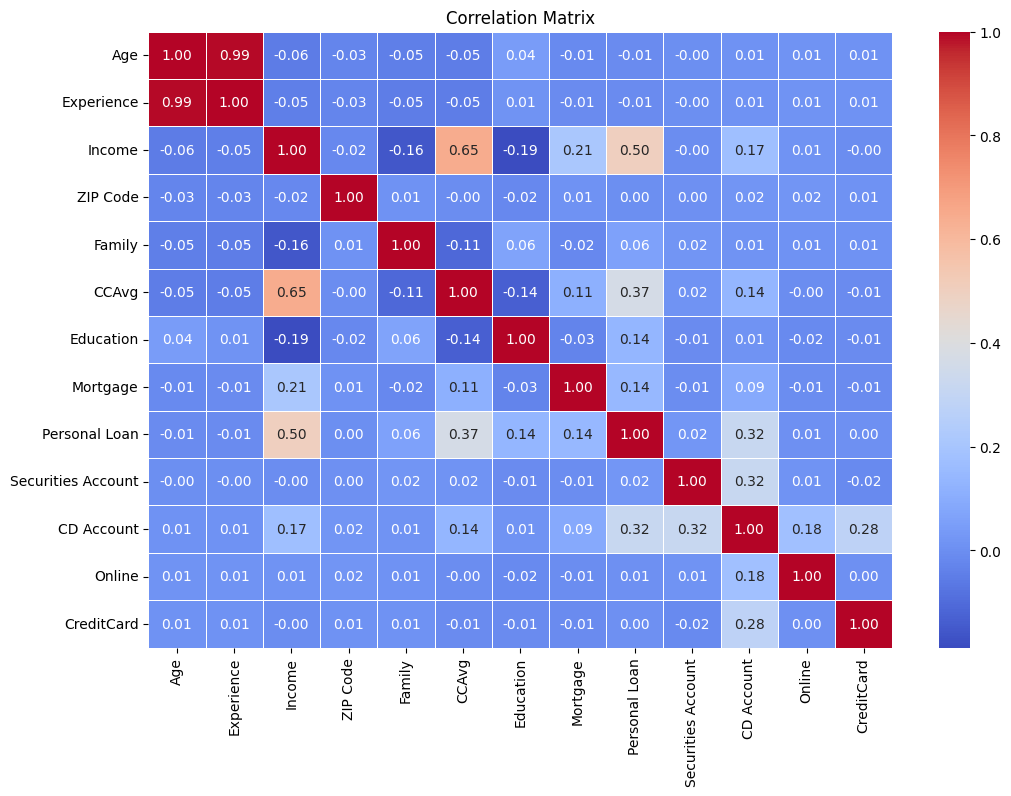

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

Predicted Classes: [0 0 0 0 0 0 0 0 0 0]
Predicted Probabilities: [2.000e-04 2.629e-01 2.380e-02 1.000e-04 1.800e-03 1.900e-03 3.770e-02
 9.900e-03 9.800e-03 6.070e-02] 

Logistic Regression Accuracy: 0.955
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       895
           1       0.87      0.68      0.76       105

    accuracy                           0.95      1000
   macro avg       0.91      0.83      0.87      1000
weighted avg       0.95      0.95      0.95      1000



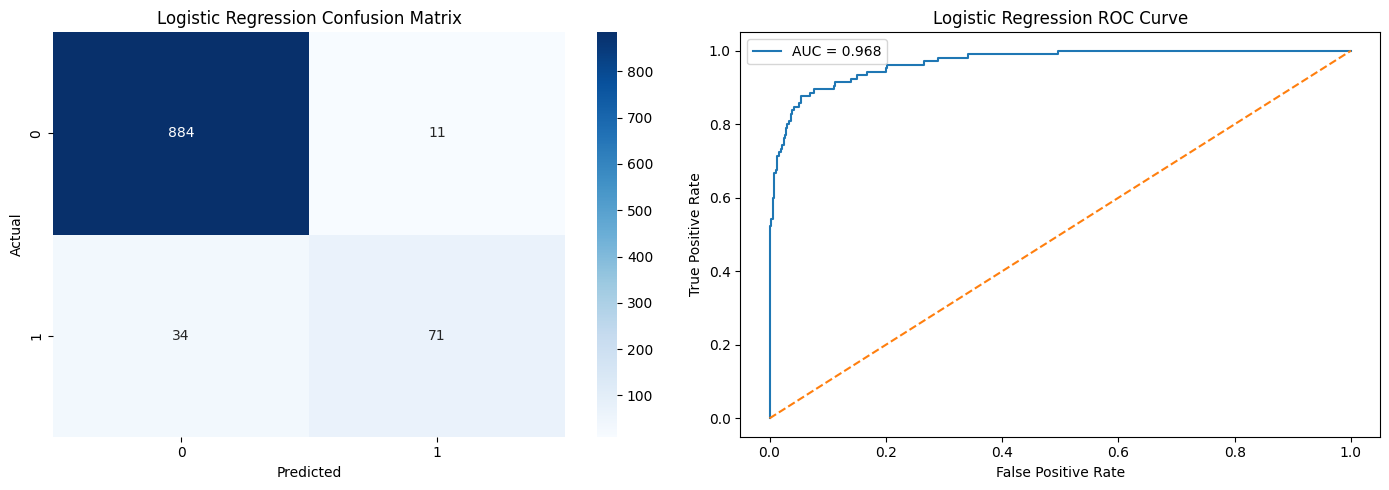

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

def evaluate(name, y_true, y_pred, y_prob, cmap):
    print(f"{name} Accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred))
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap=cmap, ax=axes[0])
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    axes[0].set_title(f"{name} Confusion Matrix")
    axes[1].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
    axes[1].plot([0, 1], [0, 1], '--')
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{name} ROC Curve")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

log_model = LogisticRegression()
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

print("Predicted Classes:", y_pred[:10])
print("Predicted Probabilities:", y_prob[:10].round(4), "\n")

evaluate("Logistic Regression", y_test, y_pred, y_prob, 'Blues')

,Feature,Coefficient
2,Income,2.396703
6,Education,1.337324
9,CD Account,0.897669
4,Family,0.817753
1,Experience,0.405972
5,CCAvg,0.188878
7,Mortgage,0.054500
3,ZIP Code,-0.084800
8,Securities Account,-0.265740
0,Age,-0.280244


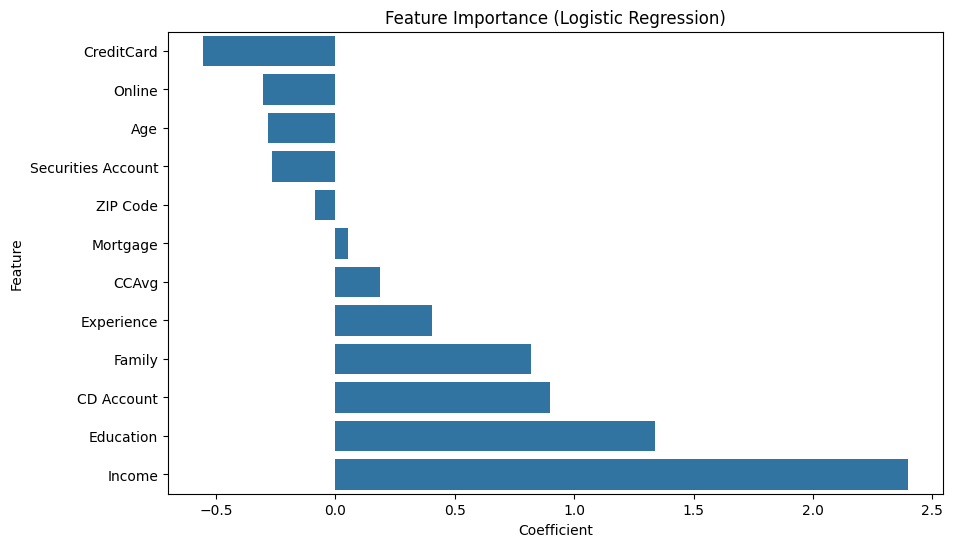

In [12]:
coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

display(coeff_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coeff_df.sort_values(by='Coefficient'))
plt.title("Feature Importance (Logistic Regression)")
plt.show()

In [13]:
log_model_l2 = LogisticRegression(penalty='l2')
log_model_l2.fit(X_train, y_train)

log_model_l1 = LogisticRegression(penalty='l1', solver='liblinear')
log_model_l1.fit(X_train, y_train)

print("L2 Accuracy:", accuracy_score(y_test, log_model_l2.predict(X_test)))
print("L1 Accuracy:", accuracy_score(y_test, log_model_l1.predict(X_test)))

L2 Accuracy: 0.955
L1 Accuracy: 0.955


In [14]:
sample = pd.DataFrame(
    [[45, 20, 60, 400001, 2, 1.5, 2, 0, 1, 0, 1, 0]],
    columns=X.columns
)

sample_scaled = scaler.transform(sample)
prediction = log_model.predict(sample_scaled)[0]
probability = log_model.predict_proba(sample_scaled)[0][1]

print("Predicted Class:", prediction)
print("Probability of Loan Acceptance:", probability)

if prediction == 1:
    print(f"Customer is LIKELY to accept the loan (Confidence: {probability:.2f})")
else:
    print(f"Customer is NOT likely to accept the loan (Confidence: {1 - probability:.2f})")

Predicted Class: 0
Probability of Loan Acceptance: 8.321721118418785e-09
Customer is NOT likely to accept the loan (Confidence: 1.00)


In [15]:
fields = [
    "Age", "Experience", "Income", "ZIP Code", "Family", "CCAvg",
    "Education (1/2/3)", "Mortgage", "Securities Account (0/1)",
    "CD Account (0/1)", "Online (0/1)", "Credit Card (0/1)"
]

values = [float(input(f"Enter {field}: ")) for field in fields]

user_input = pd.DataFrame([values], columns=X.columns)
user_scaled = scaler.transform(user_input)

pred = log_model.predict(user_scaled)[0]
prob = log_model.predict_proba(user_scaled)[0][1]

print("\nPrediction:", pred)
print("Probability:", prob)

if pred == 1:
    print(f"Customer is LIKELY to take the loan (Confidence: {prob:.2f})")
else:
    print(f"Customer is NOT likely to take the loan (Confidence: {1 - prob:.2f})")

Enter Age: 25
Enter Experience: 5
Enter Income: 25000
Enter ZIP Code: 5
Enter Family: 5
Enter CCAvg: 65
Enter Education (1/2/3): 2
Enter Mortgage: 8
Enter Securities Account (0/1): 1
Enter CD Account (0/1): 1
Enter Online (0/1): 1
Enter Credit Card (0/1): 1

Prediction: 1
Probability: 1.0
Customer is LIKELY to take the loan (Confidence: 1.00)


SVM (RBF) Accuracy: 0.976
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       895
           1       0.97      0.80      0.88       105

    accuracy                           0.98      1000
   macro avg       0.97      0.90      0.93      1000
weighted avg       0.98      0.98      0.97      1000



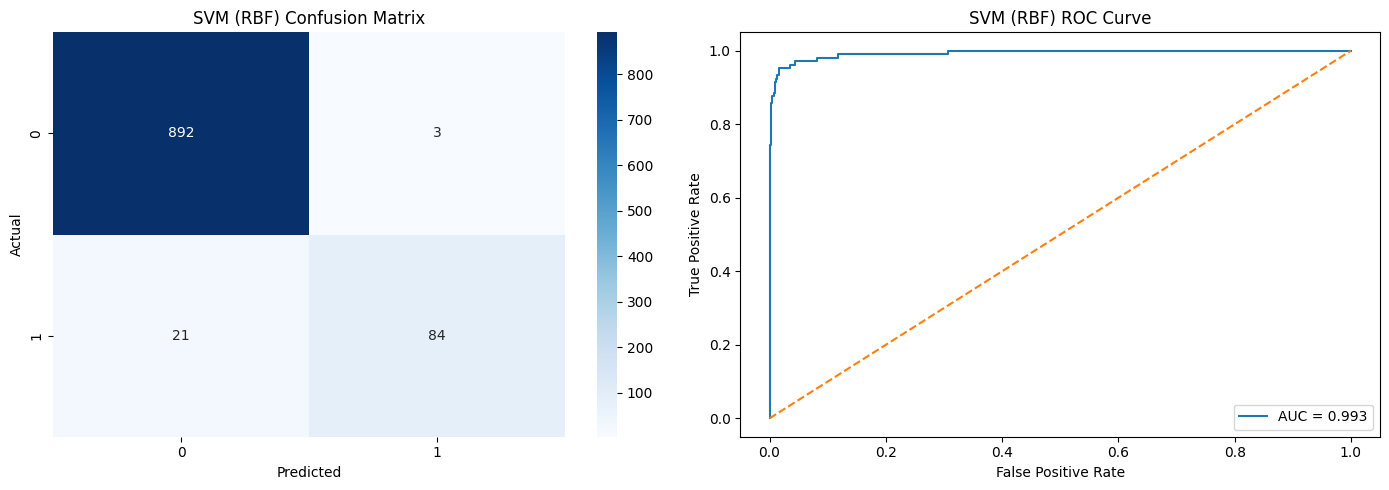

In [17]:
from sklearn.svm import SVC

svm_linear = SVC(kernel='linear', probability=True)
svm_linear.fit(X_train, y_train)

svm_rbf = SVC(kernel='rbf', probability=True)
svm_rbf.fit(X_train, y_train)

y_pred_svm = svm_rbf.predict(X_test)
y_prob_svm = svm_rbf.predict_proba(X_test)[:, 1]

evaluate("SVM (RBF)", y_test, y_pred_svm, y_prob_svm, 'Blues')

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


,0
Age,0
Experience,0
Income,0
ZIP Code,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0
Securities Account,0


,count
Personal Loan,
0,4520
1,480


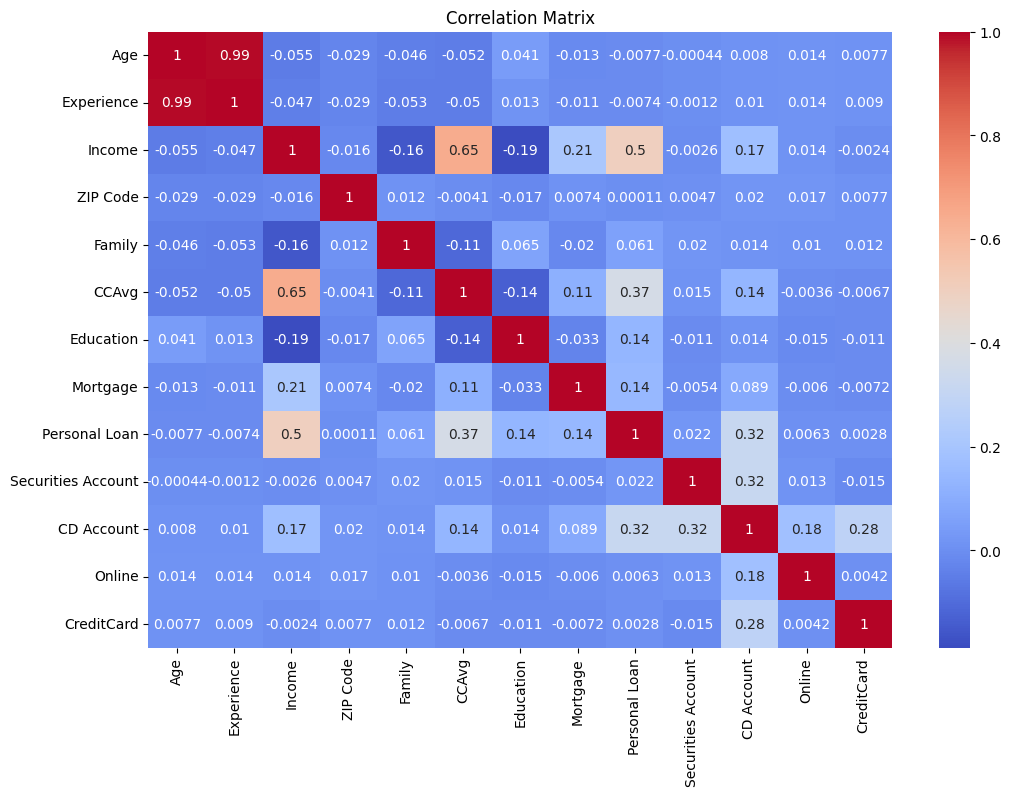

Index(['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object') Index([], dtype='object')
Predicted Classes:
 [0 0 0 0 0 0 0 0 0 0]

Predicted Probabilities:
 [1.97238707e-04 2.62882796e-01 2.37566530e-02 1.43758210e-04
 1.79923982e-03 1.88188494e-03 3.77366054e-02 9.94079377e-03
 9.82541659e-03 6.06853638e-02]
Accuracy: 0.955


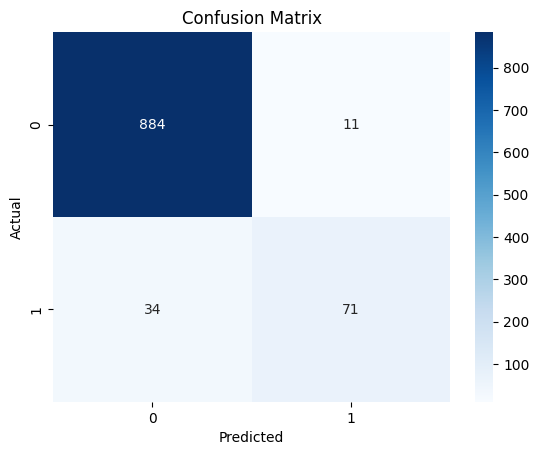

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       895
           1       0.87      0.68      0.76       105

    accuracy                           0.95      1000
   macro avg       0.91      0.83      0.87      1000
weighted avg       0.95      0.95      0.95      1000



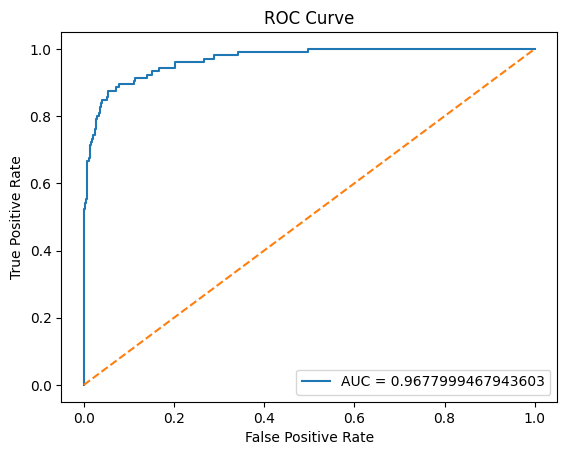

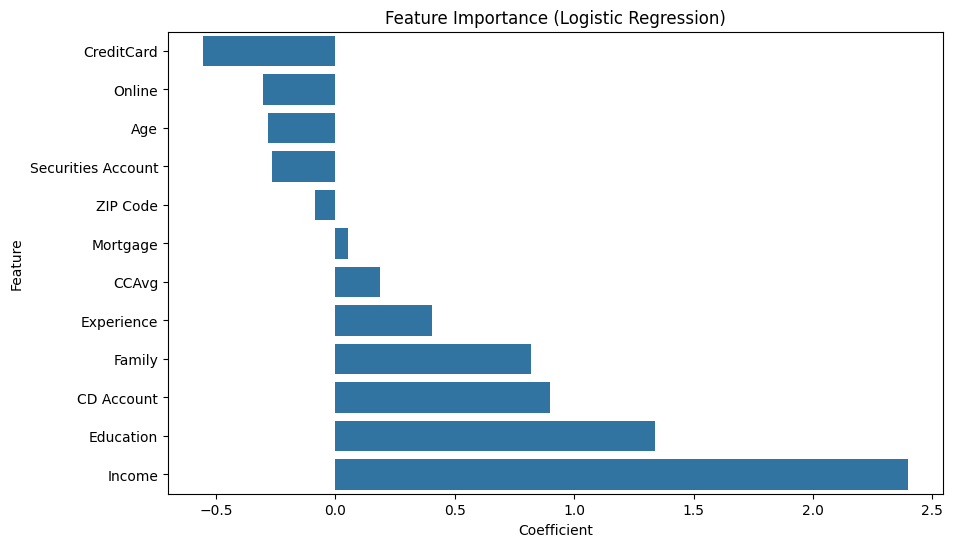

,Feature,Coefficient
2,Income,2.396703
6,Education,1.337324
9,CD Account,0.897669
4,Family,0.817753
1,Experience,0.405972
5,CCAvg,0.188878
7,Mortgage,0.054500
3,ZIP Code,-0.084800
8,Securities Account,-0.265740
0,Age,-0.280244


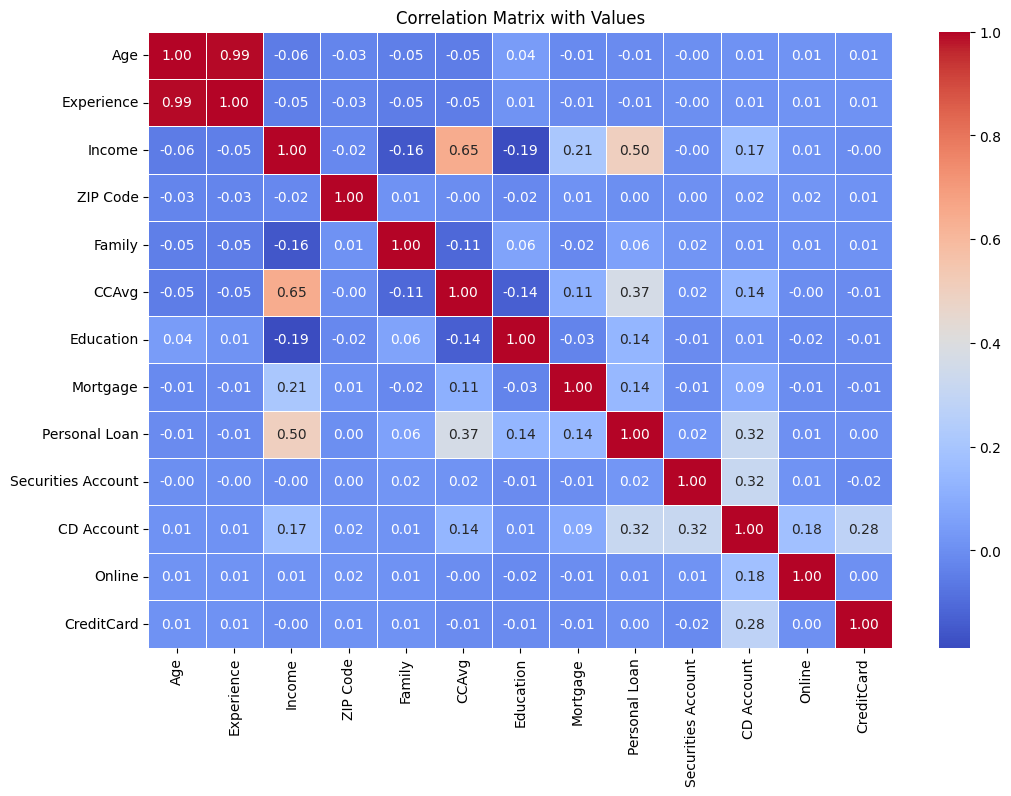

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


L2 Accuracy: 0.955
L1 Accuracy: 0.955
Classification Report (Multivariate Logistic Regression):

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       895
           1       0.87      0.68      0.76       105

    accuracy                           0.95      1000
   macro avg       0.91      0.83      0.87      1000
weighted avg       0.95      0.95      0.95      1000

Index(['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online',
       'CreditCard'],
      dtype='object')
Predicted Class: 0
Probability of Loan Acceptance: 8.321721118418785e-09
Customer is NOT likely to accept the loan (Confidence: 1.00)
Enter Age: 25
Enter Experience: 5
Enter Income: 5
Enter ZIP Code: 25
Enter Family size: 5
Enter CCAvg: 64
Enter Education (1/2/3): 2
Enter Mortgage: 8
Securities Account (0/1): 0
CD Account (0/1): 1
Online (0/1): 1
Credit Card (0/1): 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



Prediction: 1
Probability: 0.9988825435207643
❌ Customer is NOT likely to take the loan (Confidence: 1.00)
SVM Accuracy: 0.976


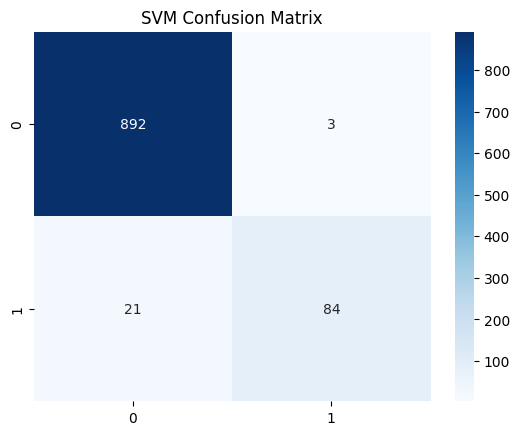

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       895
           1       0.97      0.80      0.88       105

    accuracy                           0.98      1000
   macro avg       0.97      0.90      0.93      1000
weighted avg       0.98      0.98      0.97      1000



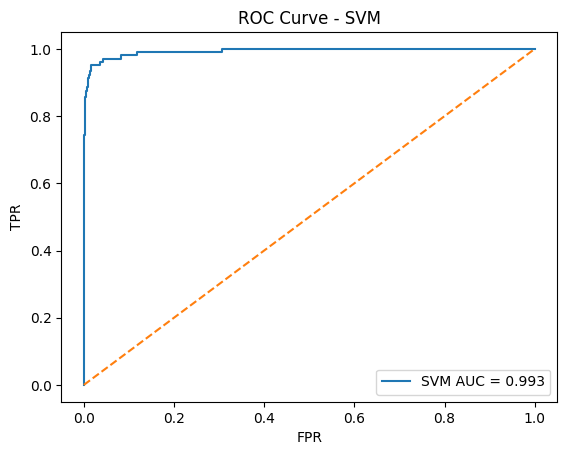

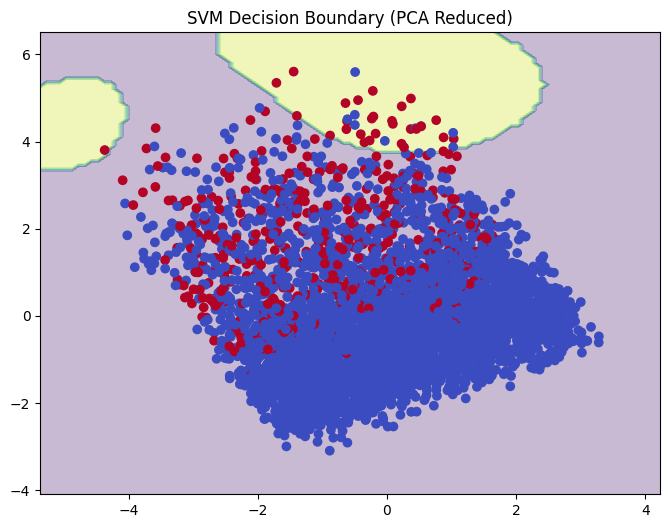

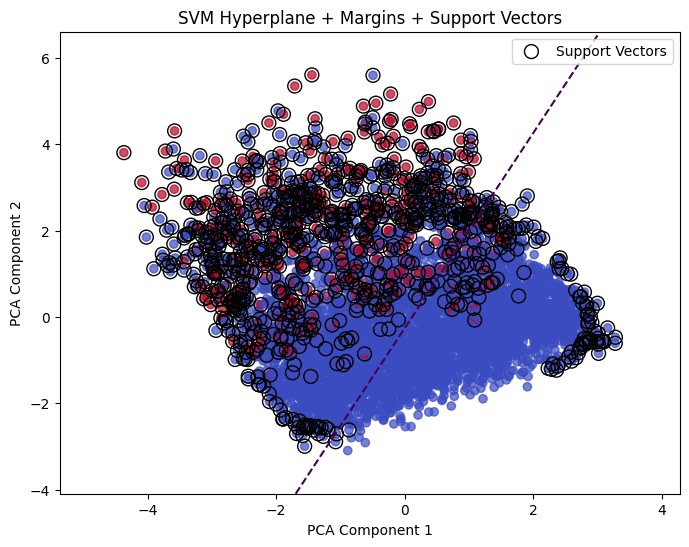

Decision Tree Accuracy: 0.986


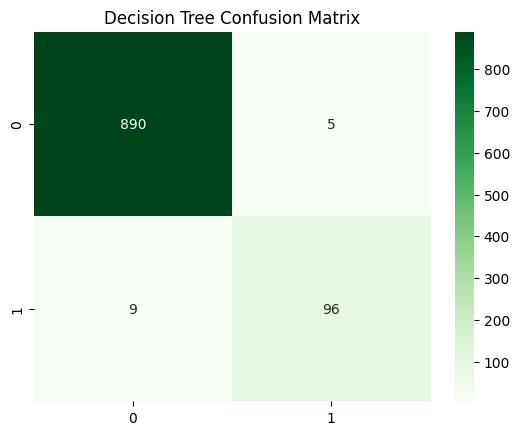

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       895
           1       0.95      0.91      0.93       105

    accuracy                           0.99      1000
   macro avg       0.97      0.95      0.96      1000
weighted avg       0.99      0.99      0.99      1000



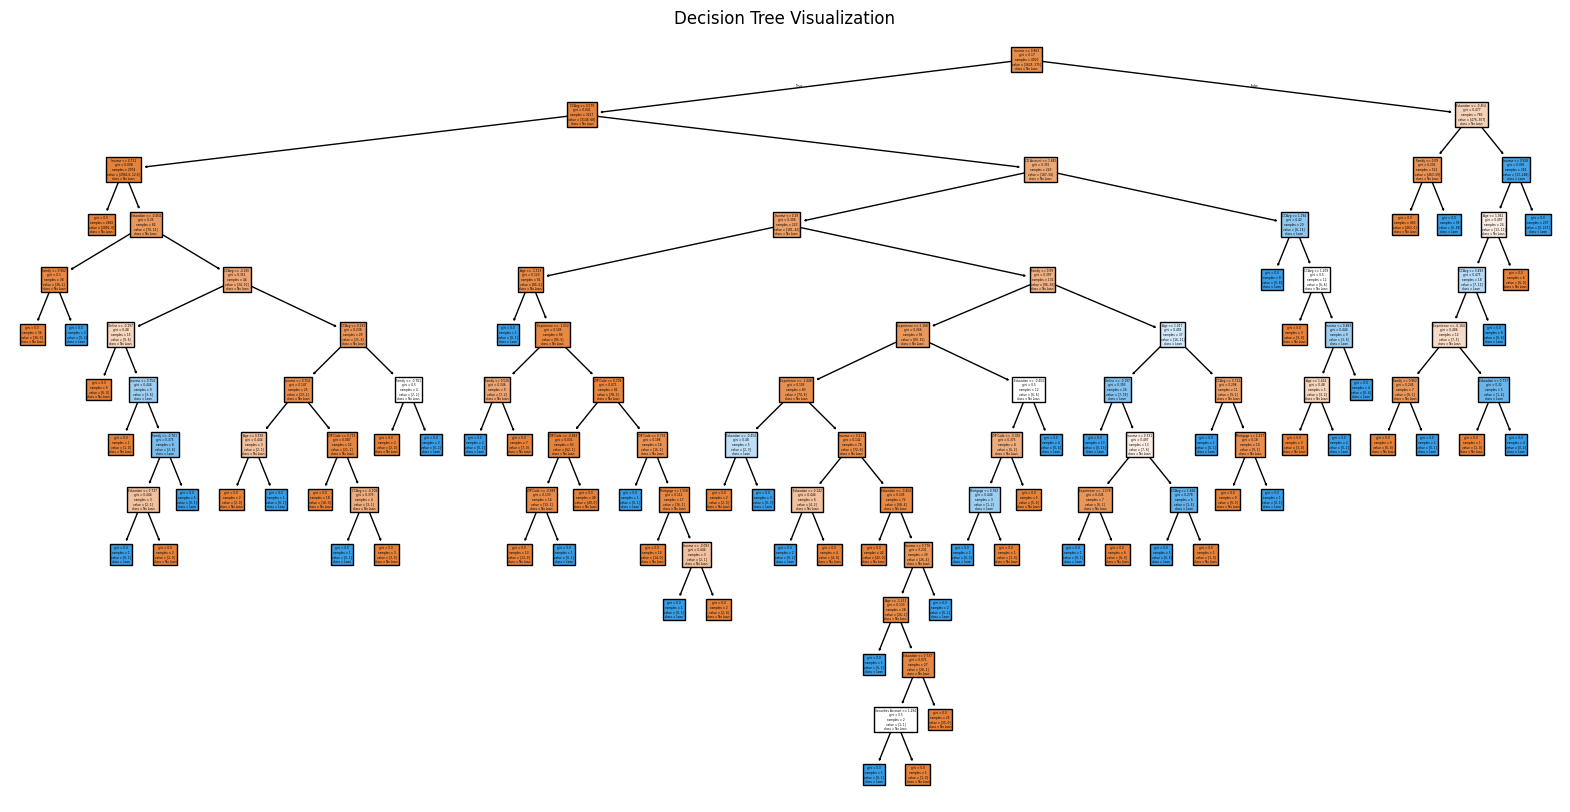

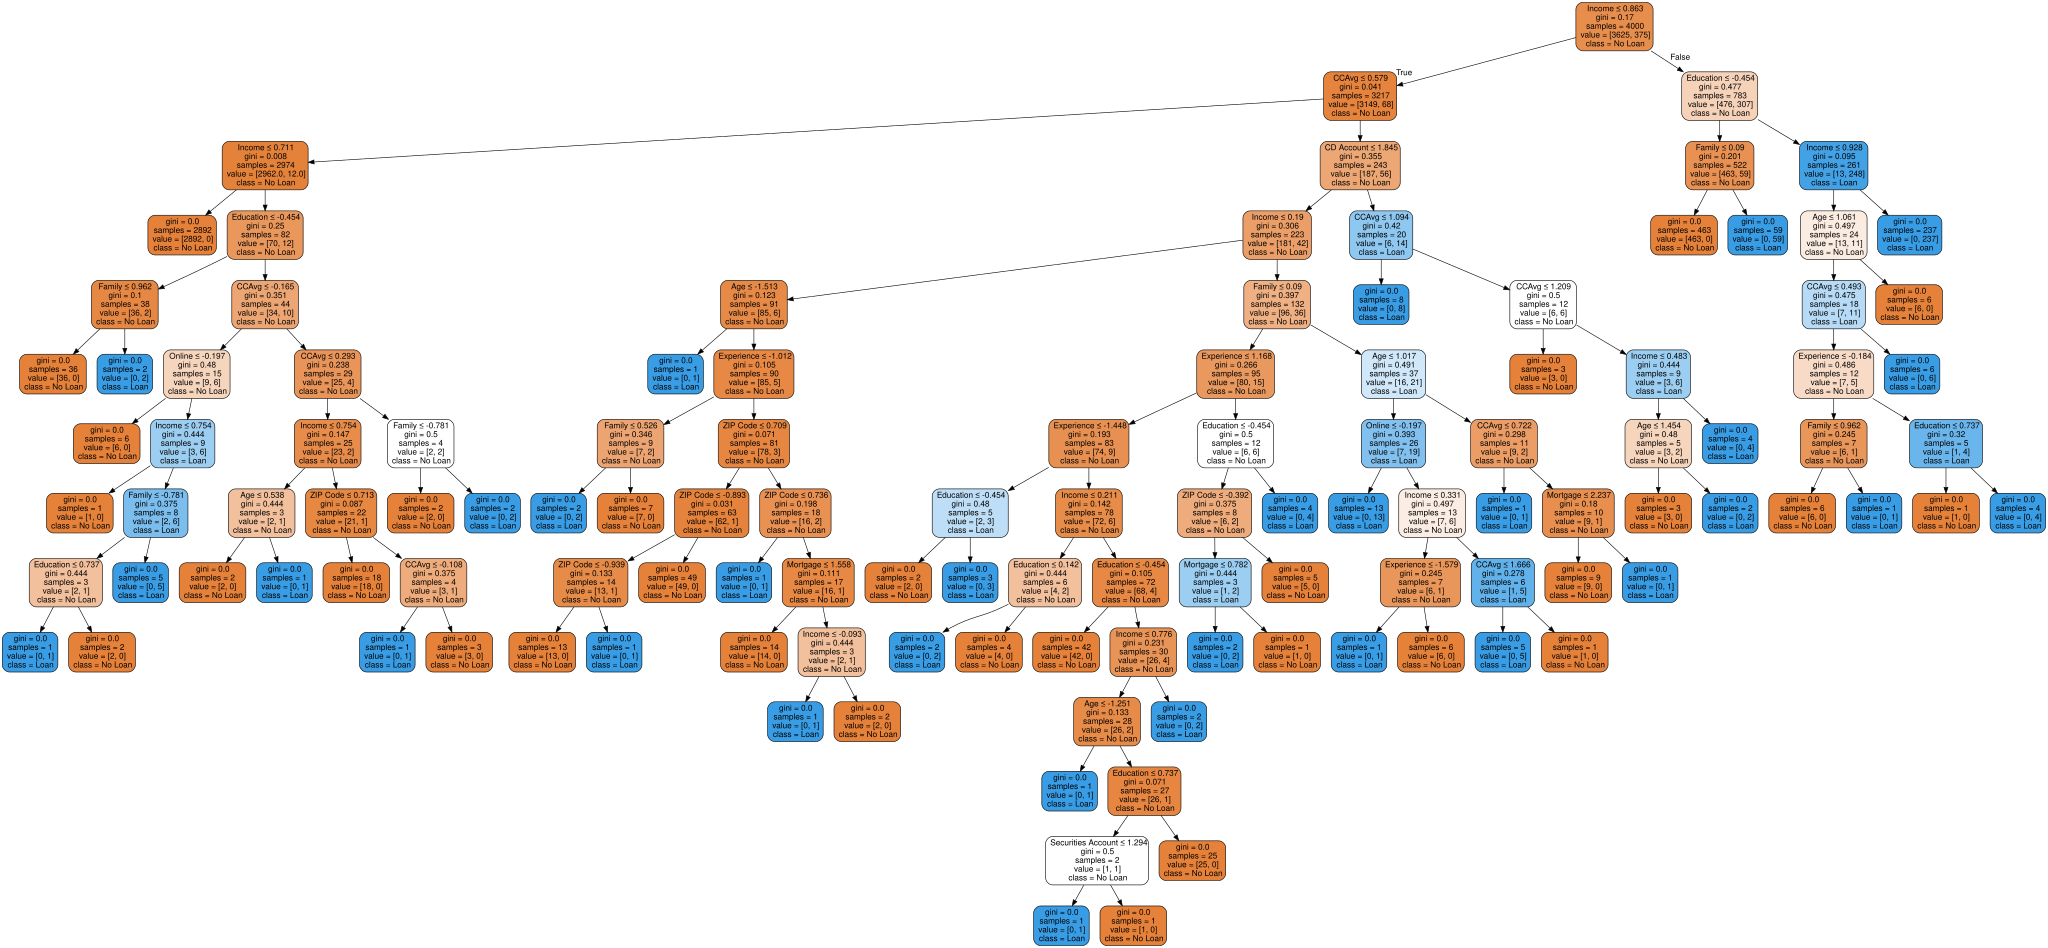

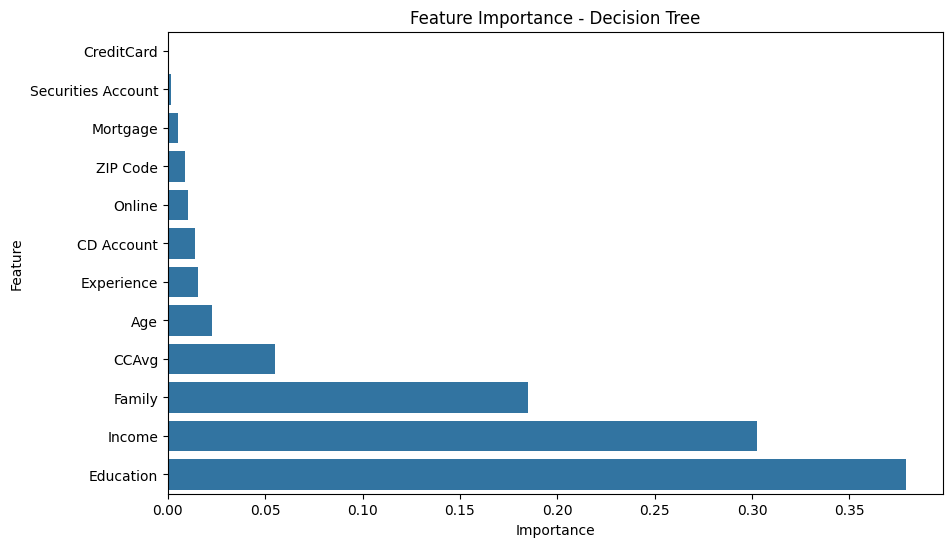

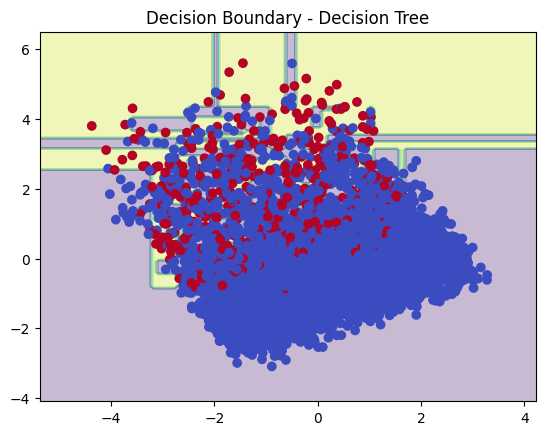

,Feature,Importance
6,Education,0.379124
2,Income,0.302545
4,Family,0.185207
5,CCAvg,0.054980
0,Age,0.022519
1,Experience,0.015559
9,CD Account,0.014139
10,Online,0.010254
3,ZIP Code,0.008785
7,Mortgage,0.005418


In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import graphviz
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, roc_curve, auc
)

# Added errors='ignore' to prevent KeyError if 'ID' is already dropped
df.drop(columns=['ID'], errors='ignore', inplace=True)
df.drop_duplicates(inplace=True)

display(df.head())
display(df.isnull().sum())
display(df['Personal Loan'].value_counts())

num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

print(num_cols, cat_cols)

X = df.drop('Personal Loan', axis=1)
y = df['Personal Loan']

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

log_model = LogisticRegression()

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

y_prob = log_model.predict_proba(X_test)[:, 1]
print("Predicted Classes:\n", y_pred[:10])
print("\nPredicted Probabilities:\n", y_prob[:10])

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_model.coef_[0]
})

plt.figure(figsize=(10,6))
sns.barplot(x='Coefficient', y='Feature', data=coeff_df.sort_values(by='Coefficient'))
plt.title("Feature Importance (Logistic Regression)")
plt.show()

display(coeff_df.sort_values(by='Coefficient', ascending=False))

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Correlation Matrix with Values")
plt.show()

log_model_l2 = LogisticRegression(penalty='l2')
log_model_l2.fit(X_train, y_train)

log_model_l1 = LogisticRegression(penalty='l1', solver='liblinear')
log_model_l1.fit(X_train, y_train)

print("L2 Accuracy:", accuracy_score(y_test, log_model_l2.predict(X_test)))
print("L1 Accuracy:", accuracy_score(y_test, log_model_l1.predict(X_test)))

y_pred_multi = log_model.predict(X_test)

print("Classification Report (Multivariate Logistic Regression):\n")
print(classification_report(y_test, y_pred_multi))

print(X.columns)

sample = [[45, 20, 60, 400001, 2, 1.5, 2, 0, 1, 0, 1, 0]]

sample_scaled = scaler.transform(sample)

prediction = log_model.predict(sample_scaled)
probability = log_model.predict_proba(sample_scaled)[0][1]

print("Predicted Class:", prediction[0])
print("Probability of Loan Acceptance:", probability)

if prediction[0] == 1:
    print(f"Customer is LIKELY to accept the loan (Confidence: {probability:.2f})")
else:
    print(f"Customer is NOT likely to accept the loan (Confidence: {1 - probability:.2f})")

age = float(input("Enter Age: "))
experience = float(input("Enter Experience: "))
income = float(input("Enter Income: "))
zip_code = float(input("Enter ZIP Code: "))
family = float(input("Enter Family size: "))
ccavg = float(input("Enter CCAvg: "))
education = float(input("Enter Education (1/2/3): "))
mortgage = float(input("Enter Mortgage: "))
securities = float(input("Securities Account (0/1): "))
cd = float(input("CD Account (0/1): "))
online = float(input("Online (0/1): "))
credit = float(input("Credit Card (0/1): "))

user_input = [[age, experience, income, zip_code, family, ccavg,
               education, mortgage, securities, cd, online, credit]]

user_scaled = scaler.transform(user_input)

pred = log_model.predict(user_scaled)
prob = log_model.predict_proba(user_scaled)[0][1]

print("\nPrediction:", pred[0])
print("Probability:", prob)

if prediction[0] == 1:
    print(f"✅ Customer is LIKELY to take the loan (Confidence: {probability:.2f})")
else:
    print(f"❌ Customer is NOT likely to take the loan (Confidence: {1 - probability:.2f})")

svm_linear = SVC(kernel='linear', probability=True)

svm_linear.fit(X_train, y_train)

svm_rbf = SVC(kernel='rbf', probability=True)

svm_rbf.fit(X_train, y_train)

y_pred_svm = svm_rbf.predict(X_test)
y_prob_svm = svm_rbf.predict_proba(X_test)[:,1]

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

cm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("SVM Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_svm))

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = auc(fpr_svm, tpr_svm)

plt.plot(fpr_svm, tpr_svm, label=f"SVM AUC = {auc_svm:.3f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

svm_vis = SVC(kernel='rbf')
svm_vis.fit(X_pca, y)

x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = svm_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm')
plt.title("SVM Decision Boundary (PCA Reduced)")
plt.show()

svm_vis = SVC(kernel='linear')
svm_vis.fit(X_pca, y)

x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

Z = svm_vis.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))

plt.contour(xx, yy, Z, levels=[0], linewidths=2)

plt.contour(xx, yy, Z, levels=[-1, 1], linestyles='dashed')

plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', alpha=0.7)

plt.scatter(
    svm_vis.support_vectors_[:,0],
    svm_vis.support_vectors_[:,1],
    s=100,
    facecolors='none',
    edgecolors='k',
    label='Support Vectors'
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("SVM Hyperplane + Margins + Support Vectors")
plt.legend()
plt.show()

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Decision Tree Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_dt))

plt.figure(figsize=(20,10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['No Loan', 'Loan'],
    filled=True
)

plt.title("Decision Tree Visualization")
plt.show()

dot_data = export_graphviz(
    dt_model,
    out_file=None,
    feature_names=X.columns,
    class_names=['No Loan', 'Loan'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)
display(graph)

dt_model_limited = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

dt_model_limited.fit(X_train, y_train)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance.sort_values(by='Importance')
)

plt.title("Feature Importance - Decision Tree")
plt.show()

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

dt_vis = DecisionTreeClassifier()
dt_vis.fit(X_pca, y)

x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = dt_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm')
plt.title("Decision Boundary - Decision Tree")
plt.show()

display(importance.sort_values(by='Importance', ascending=False))